# 04 · Holidays: where does presence shift?

Output 2 (applied analysis). The question for a user of the data, such as a tourism office: which places gain visitors on public holidays, compared with an ordinary day of the same weekday?

Two levels:

- 500 m grid cells (`grid_daily`, lattice-artifact cells excluded), measure `share_of_diy_day`.
- Kapanewon (`hourly_kapanewon` summed over the day), measure the kapanewon's share of DIY device-hours.

A shift is a holiday's share minus a baseline: the mean share on the same weekday 1 and 2 weeks before and after, leaving out holidays and days in a different panel segment, with at least 2 such days (`src/applied.py`, `baseline_days`). PLAN.md section 2 proposed "1 and 2 weeks before" only; that baseline would compare 1 Jan (segment S2) with December (S1), across a panel break, so this notebook uses the same window as the `dev_*` columns in `build_features.py` instead. 29 Apr has no valid baseline and is left out, which leaves 6 holidays.

Shares move from day to day even without a holiday, because the panel is small. Every holiday shift is therefore compared with the same calculation on ordinary days (a placebo).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from config import FIGURES as FIG, KAB_ORDER, PLACES_CSV, PROCESSED
from applied import baseline_days, shifts

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.width", 160, "display.max_columns", 30)
JP_COL = "#0F766E"            # slide colours (presentation/slides_plan.md)
FIGSIZE = (12.8, 7.2)         # 1920 x 1080 at 150 dpi
M_PER_DEG = 111_000
rng = np.random.default_rng(0)

daily = pd.read_parquet(PROCESSED / "daily_diy.parquet").set_index("date")
grid = pd.read_parquet(PROCESSED / "grid_daily.parquet",
                       columns=["cell_id", "date", "centroid_lat", "centroid_lon",
                                "lattice_artifact", "share_of_diy_day"])
hourly = pd.read_parquet(PROCESSED / "hourly_kapanewon.parquet",
                         columns=["date", "kab_kota", "kapanewon_code", "kapanewon", "n_maids"])
# daily_diy stores dates as ns, the others as us; align them so lookups by date match.
for df in (grid, hourly):
    df["date"] = df["date"].astype("datetime64[ns]")
places = pd.read_csv(PLACES_CSV)

grid = grid[~grid.lattice_artifact]
cells = grid.drop_duplicates("cell_id").set_index("cell_id")[["centroid_lat", "centroid_lon"]]
days_published = grid.groupby("cell_id").date.nunique()
# A missing cell-day had fewer than 5 devices, so its share is close to 0.
cell_share = grid.pivot_table(index="date", columns="cell_id", values="share_of_diy_day").fillna(0) * 100
assert cell_share.index.equals(daily.index)

kap_dev = hourly.groupby(["date", "kapanewon_code"]).n_maids.sum().unstack(fill_value=0)
kap_share = kap_dev.div(kap_dev.sum(axis=1), axis=0) * 100
names = hourly.drop_duplicates("kapanewon_code").set_index("kapanewon_code")[["kab_kota", "kapanewon"]]

def savefig(fig, name):
    fig.savefig(FIG / f"holiday_{name}.png")

print(f"{cell_share.shape[1]:,} non-artifact cells, {kap_share.shape[1]} kapanewon, {len(daily)} days")

5,645 non-artifact cells, 78 kapanewon, 151 days


## 1. Baseline and shifts for every day

In [2]:
cell_shift = shifts(cell_share, daily)   # percentage points of DIY presence
kap_shift = shifts(kap_share, daily)
holidays = daily.index[daily.is_holiday].intersection(cell_shift.index)
ordinary = cell_shift.index[~daily.is_holiday.reindex(cell_shift.index)]
weekend_ordinary = ordinary[daily.is_weekend.reindex(ordinary)]
print("Days with a baseline:", len(cell_shift), "| holidays:", len(holidays),
      "| ordinary days:", len(ordinary), "| ordinary weekend days:", len(weekend_ordinary))
display(daily.loc[holidays, ["holiday_name", "day_of_week", "panel_segment"]]
        .assign(baseline=[", ".join(d.strftime("%d %b") for d in baseline_days(h, daily)) for h in holidays]))

Days with a baseline: 146 | holidays: 6 | ordinary days: 140 | ordinary weekend days: 41


,holiday_name,day_of_week,panel_segment,baseline
date,,,,
2021-12-25,Christmas,5,S1 Dec,"11 Dec, 18 Dec"
2022-01-01,New Year,5,S2 1 Jan-15 Feb,"08 Jan, 15 Jan"
2022-02-01,Imlek (Chinese New Year 2573),1,S2 1 Jan-15 Feb,"18 Jan, 25 Jan, 08 Feb, 15 Feb"
2022-02-28,Isra Mi'raj,0,S3 16 Feb-Apr,"21 Feb, 07 Mar, 14 Mar"
2022-03-03,Nyepi (Saka New Year 1944),3,S3 16 Feb-Apr,"17 Feb, 24 Feb, 10 Mar, 17 Mar"
2022-04-15,Good Friday,4,S3 16 Feb-Apr,"01 Apr, 08 Apr, 22 Apr"


## 2. Do holidays rearrange presence more than ordinary days?

The redistribution index of a day is the sum of all positive cell shifts: the percentage of DIY presence that sits in different cells than on a normal day of the same weekday (it equals the sum of the negative shifts, with opposite sign). If holidays send people to different places, holidays should have a higher index than ordinary days.

In [3]:
redistribution = cell_shift.clip(lower=0).sum(axis=1)
kap_redistribution = kap_shift.clip(lower=0).sum(axis=1)
tbl = pd.DataFrame({
    "grid cells: mean": [redistribution[holidays].mean(), redistribution[weekend_ordinary].mean(),
                         redistribution[ordinary].mean()],
    "grid cells: max": [redistribution[holidays].max(), redistribution[weekend_ordinary].max(),
                        redistribution[ordinary].max()],
    "kapanewon: mean": [kap_redistribution[holidays].mean(), kap_redistribution[weekend_ordinary].mean(),
                        kap_redistribution[ordinary].mean()],
}, index=["holidays", "ordinary weekend days", "all ordinary days"]).round(1)
print("Redistribution index (% of DIY presence that moved):")
display(tbl)
print("Holidays:", redistribution[holidays].round(1).to_dict())
pct_rank = {h.date(): (redistribution[ordinary] < redistribution[h]).mean() * 100 for h in holidays}
print("Percentile of each holiday among ordinary days (grid):", {k: round(v) for k, v in pct_rank.items()})

Redistribution index (% of DIY presence that moved):


,grid cells: mean,grid cells: max,kapanewon: mean
holidays,26.1,29.7,10.2
ordinary weekend days,24.2,41.0,10.0
all ordinary days,24.7,48.9,9.9


Holidays: {Timestamp('2021-12-25 00:00:00'): 25.0, Timestamp('2022-01-01 00:00:00'): 29.7, Timestamp('2022-02-01 00:00:00'): 27.4, Timestamp('2022-02-28 00:00:00'): 24.3, Timestamp('2022-03-03 00:00:00'): 25.3, Timestamp('2022-04-15 00:00:00'): 24.9}
Percentile of each holiday among ordinary days (grid): {datetime.date(2021, 12, 25): 61, datetime.date(2022, 1, 1): 89, datetime.date(2022, 2, 1): 75, datetime.date(2022, 2, 28): 53, datetime.date(2022, 3, 3): 62, datetime.date(2022, 4, 15): 59}


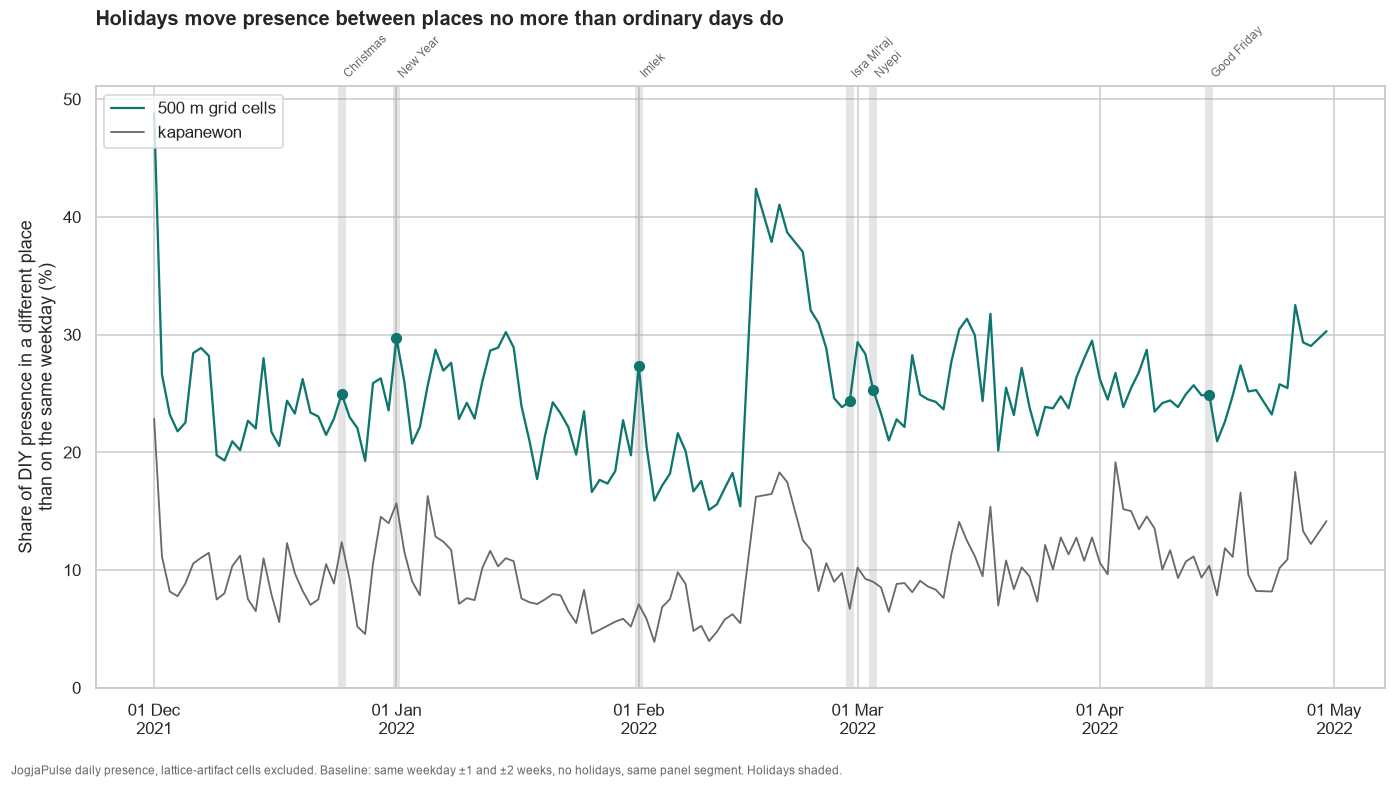

In [4]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(redistribution.index, redistribution, color=JP_COL, lw=1.5, label="500 m grid cells")
ax.plot(kap_redistribution.index, kap_redistribution, color="dimgrey", lw=1.2, label="kapanewon")
ax.scatter(holidays, redistribution[holidays], color=JP_COL, zorder=3, s=40)
for h in holidays:
    ax.axvspan(h - pd.Timedelta(hours=12), h + pd.Timedelta(hours=12), color="grey", alpha=.2, lw=0)
    ax.text(h, 1.01, daily.holiday_name[h].split(" (")[0], rotation=45, fontsize=8, color="dimgrey",
            transform=ax.get_xaxis_transform(), ha="left", va="bottom")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))
ax.set_ylabel("Share of DIY presence in a different place\nthan on the same weekday (%)")
ax.set_ylim(0)
ax.legend(loc="upper left")
ax.set_title("Holidays move presence between places no more than ordinary days do", loc="left", pad=40)
fig.text(.01, .01, "JogjaPulse daily presence, lattice-artifact cells excluded. Baseline: same weekday "
         "±1 and ±2 weeks, no holidays, same panel segment. Holidays shaded.", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, 1))
savefig(fig, "redistribution_series")

## 3. Cells that gain on holidays

Mean shift over the 6 holidays per cell. The placebo draws 6 ordinary weekend days at random, 1,000 times, and records the largest cell mean in each draw; a holiday top cell is only notable if it beats that.

In [5]:
N_PLACEBO = 1000
hol_mean = cell_shift.loc[holidays].mean()
hol_pos = (cell_shift.loc[holidays] > 0).sum()
placebo_max = np.array([cell_shift.loc[rng.choice(weekend_ordinary, len(holidays), replace=False)].mean().max()
                        for _ in range(N_PLACEBO)])
p95 = np.quantile(placebo_max, .95)
print(f"Largest holiday cell mean: {hol_mean.max():.2f} pp; "
      f"placebo (6 ordinary weekend days) largest cell mean: median {np.median(placebo_max):.2f}, 95th pct {p95:.2f} pp")

def nearest_place(lat, lon):
    d = np.hypot((places.lat - lat) * M_PER_DEG, (places.lon - lon) * M_PER_DEG * np.cos(np.radians(lat)))
    i = d.idxmin()
    return places.name[i], d[i] / 1000

top = (pd.DataFrame({"mean shift (pp)": hol_mean, "holidays up (of 6)": hol_pos,
                     "days published": days_published})
       .join(cells).sort_values("mean shift (pp)", ascending=False).head(10))
top[["nearest listed place", "km"]] = [nearest_place(r.centroid_lat, r.centroid_lon) for r in top.itertuples()]
top["above placebo 95%"] = top["mean shift (pp)"] > p95
by_holiday = cell_shift.loc[holidays, top.index].T.round(2)
by_holiday.columns = [h.strftime("%d %b") for h in holidays]
display(top.round({"mean shift (pp)": 3, "centroid_lat": 4, "centroid_lon": 4, "km": 1}))
print("Shift per holiday for the same cells (pp):")
display(by_holiday)

Largest holiday cell mean: 1.16 pp; placebo (6 ordinary weekend days) largest cell mean: median 1.01, 95th pct 2.42 pp


,mean shift (pp),holidays up (of 6),days published,centroid_lat,centroid_lon,nearest listed place,km,above placebo 95%
cell_id,,,,,,,,
E859_N18274,1.162,2,151,-7.8046,110.3628,Malioboro Mall,1.319037,False
E858_N18293,0.710,3,151,-7.7187,110.3584,Terminal Jombor,3.188218,False
E866_N18305,0.660,2,103,-7.6645,110.3948,Terminal Jombor,9.887172,False
E851_N18256,0.639,4,143,-7.8860,110.3264,Terminal Giwangan,9.20506,False
E859_N18279,0.334,4,151,-7.7820,110.3629,Stasiun Yogyakarta (Tugu),0.809227,False
E869_N18296,0.233,5,151,-7.7052,110.4083,Pakuwon Mall Jogja,5.969643,False
E867_N18263,0.191,1,72,-7.8544,110.3990,Terminal Giwangan,2.234154,False
E844_N18250,0.161,4,151,-7.9130,110.2946,Pantai Depok,11.150805,False
E814_N18303,0.151,2,64,-7.6731,110.1590,Terminal Jombor,23.75124,False


Shift per holiday for the same cells (pp):


,25 Dec,01 Jan,01 Feb,28 Feb,03 Mar,15 Apr
cell_id,,,,,,
E859_N18274,-0.01,-0.09,-0.15,4.56,7.38,-4.71
E858_N18293,-0.02,-0.09,0.00,2.57,3.49,-1.70
E866_N18305,-0.01,0.00,-0.02,-0.20,0.85,3.34
E851_N18256,0.01,-0.01,-0.00,1.38,0.55,1.91
E859_N18279,0.01,0.01,1.77,0.36,-0.06,-0.08
E869_N18296,0.07,0.05,0.04,0.30,-0.05,1.00
E867_N18263,-0.01,-0.01,-0.02,0.00,-0.02,1.19
E844_N18250,0.03,-0.02,0.16,-0.24,0.22,0.81
E814_N18303,0.00,0.00,-0.01,0.09,-0.18,1.01


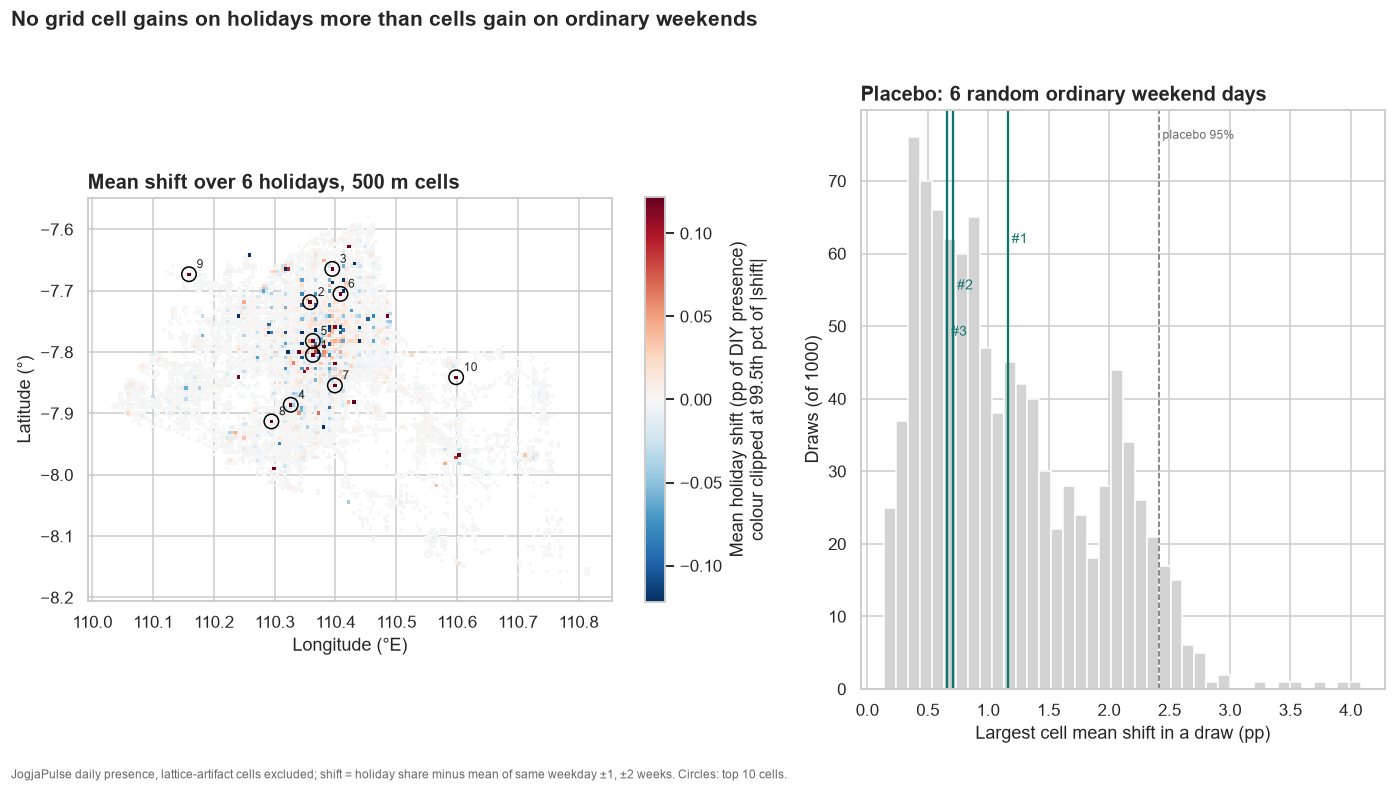

In [6]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
lim = np.quantile(hol_mean.abs(), .995)
order = hol_mean.abs().sort_values().index
sc = ax.scatter(cells.loc[order, "centroid_lon"], cells.loc[order, "centroid_lat"], c=hol_mean[order],
                cmap="RdBu_r", vmin=-lim, vmax=lim, s=5, marker="s", linewidths=0)
t10 = top.index
ax.scatter(cells.loc[t10, "centroid_lon"], cells.loc[t10, "centroid_lat"], s=90, facecolors="none",
           edgecolors="black", lw=1)
for i, c in enumerate(t10, 1):
    ax.annotate(str(i), (cells.centroid_lon[c], cells.centroid_lat[c]), xytext=(5, 4),
                textcoords="offset points", fontsize=8)
ax.set_aspect(1 / np.cos(np.radians(-7.85)))
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°)")
fig.colorbar(sc, ax=ax, shrink=.7, label="Mean holiday shift (pp of DIY presence)\ncolour clipped at 99.5th pct of |shift|")
ax.set_title("Mean shift over 6 holidays, 500 m cells", loc="left")

ax = axes[1]
ax.hist(placebo_max, bins=40, color="lightgrey", edgecolor="white")
ax.axvline(p95, color="dimgrey", ls="--", lw=1)
ax.text(p95, ax.get_ylim()[1] * .95, " placebo 95%", fontsize=8, color="dimgrey")
for i, c in enumerate(t10[:3], 1):
    ax.axvline(hol_mean[c], color=JP_COL, lw=1.5)
    ax.text(hol_mean[c], ax.get_ylim()[1] * (.85 - .08 * i), f" #{i}", color=JP_COL, fontsize=9)
ax.set_xlabel("Largest cell mean shift in a draw (pp)")
ax.set_ylabel(f"Draws (of {N_PLACEBO})")
ax.set_title("Placebo: 6 random ordinary weekend days", loc="left")
fig.suptitle("No grid cell gains on holidays more than cells gain on ordinary weekends",
             x=.01, ha="left", fontweight="bold", fontsize=14)
fig.text(.01, .01, "JogjaPulse daily presence, lattice-artifact cells excluded; shift = holiday share minus mean of "
         "same weekday ±1, ±2 weeks. Circles: top 10 cells.", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, .96))
savefig(fig, "cell_shift_map")

## 4. Kapanewon that gain on holidays

Kapanewon have more devices than single cells, so their shares are steadier. Shift here is relative: log(holiday share / baseline share), shown as %. The placebo is per kapanewon: the mean over 6 random ordinary weekend days, 1,000 draws. With 78 kapanewon, about 4 would pass a 95% cut-off by chance.

In [7]:
# A kapanewon with every hour suppressed has share 0; shifts() leaves that day out.
kap_rel = shifts(kap_share, daily, relative=True)

hol_kap = kap_rel.loc[holidays].mean()
plac = np.array([kap_rel.loc[rng.choice(weekend_ordinary, len(holidays), replace=False)].mean().values
                 for _ in range(N_PLACEBO)])
pctile = pd.Series((plac < hol_kap.values).mean(axis=0) * 100, index=hol_kap.index)
kap_tbl = (pd.DataFrame({"mean holiday shift (%)": (np.exp(hol_kap) - 1) * 100,
                         "holidays up (of 6)": (kap_rel.loc[holidays] > 0).sum(),
                         "percentile vs placebo": pctile,
                         "share of DIY (%)": kap_share.mean()})
           .join(names).sort_values("mean holiday shift (%)", ascending=False))
n_above = (pctile >= 95).sum()
n_below = (pctile <= 5).sum()
print(f"Kapanewon above the 95th placebo percentile: {n_above}; below the 5th: {n_below} (about 4 each expected by chance)")
display(kap_tbl.head(10).round(1))
display(kap_tbl.tail(5).round(1))
print("Mean shift by kabupaten (%, mean over its kapanewon):")
print(kap_tbl.groupby("kab_kota")["mean holiday shift (%)"].mean().reindex(KAB_ORDER).round(1).to_string())

Kapanewon above the 95th placebo percentile: 2; below the 5th: 6 (about 4 each expected by chance)


,mean holiday shift (%),holidays up (of 6),percentile vs placebo,share of DIY (%),kab_kota,kapanewon
kapanewon_code,,,,,,
34.03.07,72.4,4,80.5,0.1,GUNUNGKIDUL,TEPUS
34.03.16,66.0,4,78.9,0.0,GUNUNGKIDUL,GIRISUBO
34.01.08,45.6,6,99.9,0.8,KULON PROGO,KOKAP
34.03.06,42.3,4,73.2,0.1,GUNUNGKIDUL,PANGGANG
34.03.05,32.4,4,94.2,0.2,GUNUNGKIDUL,PALIYAN
34.03.14,31.1,5,80.1,0.4,GUNUNGKIDUL,GEDANGSARI
34.01.03,21.3,4,79.7,0.2,KULON PROGO,PANJATAN
34.71.05,20.4,4,95.0,0.3,YOGYAKARTA,GEDONGTENGEN
34.04.16,20.2,4,84.1,2.8,SLEMAN,PAKEM


,mean holiday shift (%),holidays up (of 6),percentile vs placebo,share of DIY (%),kab_kota,kapanewon
kapanewon_code,,,,,,
34.01.09,-27.9,0,9.5,0.2,KULON PROGO,GIRIMULYO
34.03.12,-28.5,1,1.2,0.3,GUNUNGKIDUL,SEMIN
34.04.04,-31.0,0,7.2,0.9,SLEMAN,MINGGIR
34.02.04,-33.6,2,5.6,0.5,BANTUL,PUNDONG
34.02.02,-35.6,2,3.7,0.3,BANTUL,SANDEN


Mean shift by kabupaten (%, mean over its kapanewon):
kab_kota
YOGYAKARTA      6.5
SLEMAN         -6.2
BANTUL         -3.4
KULON PROGO     1.7
GUNUNGKIDUL    11.8


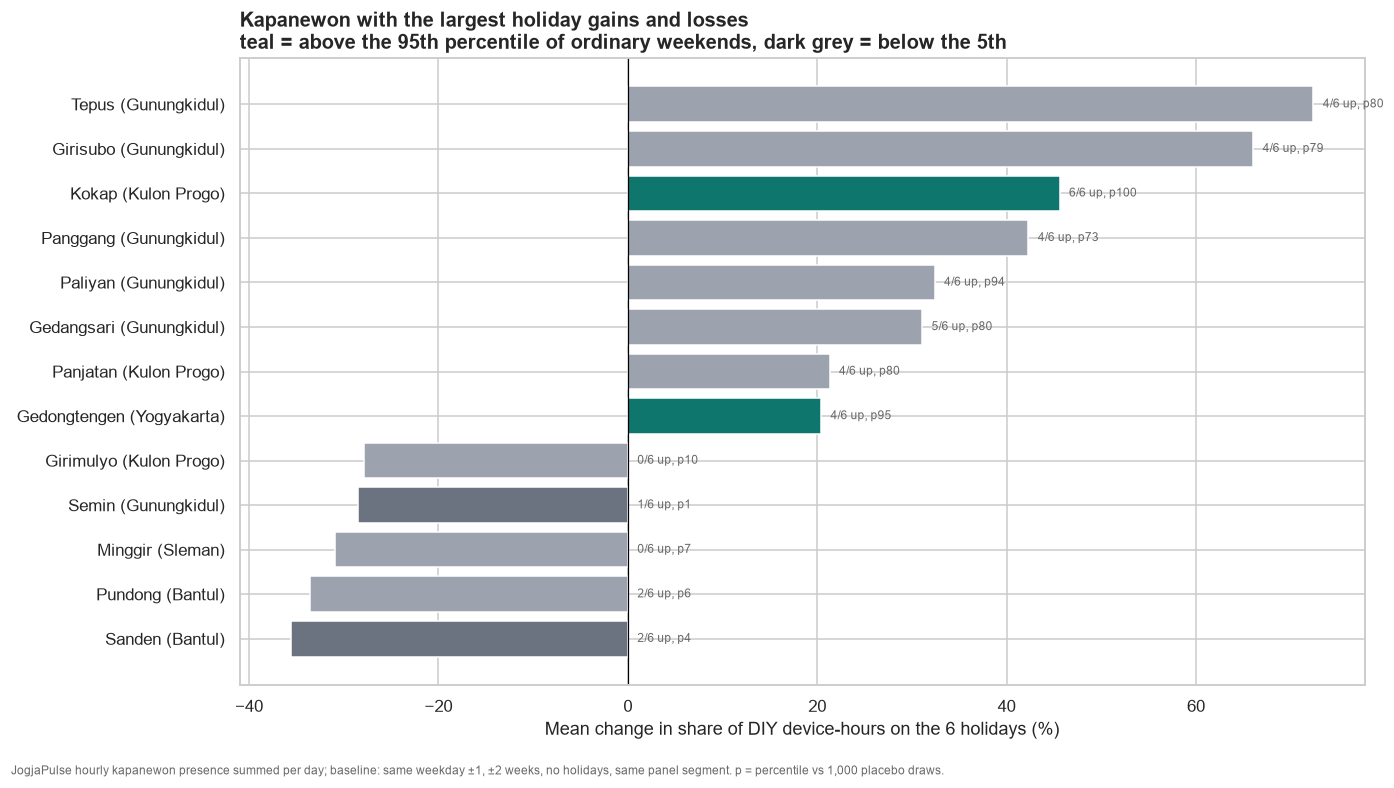

In [8]:
show = pd.concat([kap_tbl.head(8), kap_tbl.tail(5)])
fig, ax = plt.subplots(figsize=FIGSIZE)
colors = [JP_COL if p >= 95 else ("#9ca3af" if p > 5 else "#6b7280") for p in show["percentile vs placebo"]]
y = np.arange(len(show))[::-1]
ax.barh(y, show["mean holiday shift (%)"], color=colors)
ax.set_yticks(y, [f"{r.kapanewon.title()} ({r.kab_kota.title()})" for r in show.itertuples()])
for yi, r in zip(y, show.itertuples()):
    ax.text(max(r[1], 0) + 1, yi, f"{r[2]}/6 up, p{r[3]:.0f}", va="center", ha="left",
            fontsize=8, color="dimgrey")
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Mean change in share of DIY device-hours on the 6 holidays (%)")
ax.set_title("Kapanewon with the largest holiday gains and losses\n"
             "teal = above the 95th percentile of ordinary weekends, dark grey = below the 5th", loc="left")
fig.text(.01, .01, "JogjaPulse hourly kapanewon presence summed per day; baseline: same weekday ±1, ±2 weeks, "
         "no holidays, same panel segment. p = percentile vs 1,000 placebo draws.", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, 1))
savefig(fig, "kapanewon_top")

## 5. Summary numbers for the script

In [9]:
print(f"Redistribution index, grid: holidays mean {tbl.iloc[0, 0]}%, ordinary weekend days {tbl.iloc[1, 0]}%, "
      f"all ordinary days {tbl.iloc[2, 0]}%")
print(f"Top cell mean holiday shift {hol_mean.max():.2f} pp vs placebo 95th pct {p95:.2f} pp")
print(f"Kapanewon above placebo 95%: {n_above} of {len(pctile)}:",
      ", ".join(kap_tbl.loc[kap_tbl['percentile vs placebo'] >= 95, 'kapanewon'].str.title()))
for r in kap_tbl.head(3).itertuples():
    print(f"  {r.kapanewon.title()} ({r.kab_kota.title()}): {r[1]:+.0f}%, {r[2]}/6 holidays up, p{r[3]:.0f}")

Redistribution index, grid: holidays mean 26.1%, ordinary weekend days 24.2%, all ordinary days 24.7%
Top cell mean holiday shift 1.16 pp vs placebo 95th pct 2.42 pp
Kapanewon above placebo 95%: 2 of 78: Kokap, Gedongtengen
  Tepus (Gunungkidul): +72%, 4/6 holidays up, p80
  Girisubo (Gunungkidul): +66%, 4/6 holidays up, p79
  Kokap (Kulon Progo): +46%, 6/6 holidays up, p100


Interpretation (wording follows the numbers printed above):

- At 500 m resolution, holidays do not rearrange presence more than ordinary days. The redistribution index is 26.1% on holidays, 24.2% on ordinary weekends and 24.7% on all ordinary days. New Year is the highest holiday, at the 89th percentile of ordinary days.
- No single cell is a holiday hotspot. The largest mean holiday gain (1.16 pp) is below what 6 random ordinary weekend days produce at the 95th percentile (2.42 pp), and the top cells gain on one or two holidays only (28 Feb and 3 Mar). Daily cell shares move a lot because the panel is small, so the planned "top 10 holiday cells" can not be told apart from noise. F12 is reported as a negative result.
- At kapanewon level, 2 of 78 kapanewon gain more than 95% of placebo draws (Kokap, +46% and up on all 6 holidays; Gedongtengen, +20%) and 6 lose more than 95%. About 4 each would be expected by chance, so the pattern as a whole is weak.
- The largest gains are in southern Gunungkidul (Tepus +72%, Girisubo +66%), but these kapanewon hold 0.1% or less of DIY presence and sit only at the 79th-80th placebo percentile, because their shares jump on ordinary weekends too. Gunungkidul kapanewon gain 11.8% on average. This points the same way as the Gunungkidul share result in notebook 02, without being strong on its own.
- For the video: the holiday effect is visible at province level (notebook 02: Gunungkidul share +19.6% on 1 Jan) but can not be located at cell level with this data.